# Лабораторная работа № 2
## Сегментация изображений с помощью U-Net

**Цель:** реализовать U-Net, обучить её на учебном дорожном наборе CARLA и повторить эксперимент на другом наборе — CamVid с реальными фотографиями.

В работе выполнены загрузка и исследование данных, подготовка масок, обучение, графики, предсказания и оценка на отложенных изображениях. 

In [1]:
import os
import tempfile
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ.setdefault("MPLCONFIGDIR", os.path.join(tempfile.gettempdir(), "cv2-matplotlib"))
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display, Markdown
%matplotlib inline

tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.keras.utils.set_random_seed(42)

from lab2 import (conv_block, upsampling_block, unet_model, read_pair, label_colors,
                  inspect_dataset, train_model, plot_history, evaluate_model,
                  show_predictions, create_mask, worst_pairs)
from prepare_data import load_split, check_manifest, CARLA_CLASSES, CAMVID_CLASSES

RETRAIN = False  # True — заново обучить обе модели с 8 фильтрами.

print("TensorFlow:", tf.__version__)
# Проверка данных и загрузка разбиения.
check_manifest()
carla_split = load_split("carla")
camvid_split = load_split("camvid")


TensorFlow: 2.18.1


Проверены SHA-256 для 3522 файлов


## 1. Данные

**CARLA:** 1060 дорожных изображений и соответствующих масок для 23 классов. [Источник набора данных](https://github.com/Rhythm-Adhikari1/U-Net/tree/072afa362ab567ceb8c151b18b00e05ac632bf26/data).

**CamVid:** 701 дорожный кадр с пиксельной разметкой из [SegNet Tutorial](https://github.com/alexgkendall/SegNet-Tutorial/tree/bb68b64e72cb004b3ed927fee0f5624dd8097498/CamVid). Набор содержит 11 смысловых классов и служебную метку Void=11.

### Разбиение

Для CARLA используются 848 изображений для обучения, 106 для валидации и 106 для тестирования (80/10/10). Кадры с близкими номерами объединены в группы и не разделяются между частями. Это уменьшает вероятность попадания похожих соседних кадров в обучение и тест. При этом номера кадров не позволяют гарантировать независимость поездок.

Для CamVid используется опубликованное разбиение: 367 изображений для обучения, 101 для валидации и 233 для тестирования.


CARLA {'train': 848, 'val': 106, 'test': 106}
CamVid {'train': 367, 'val': 101, 'test': 233}


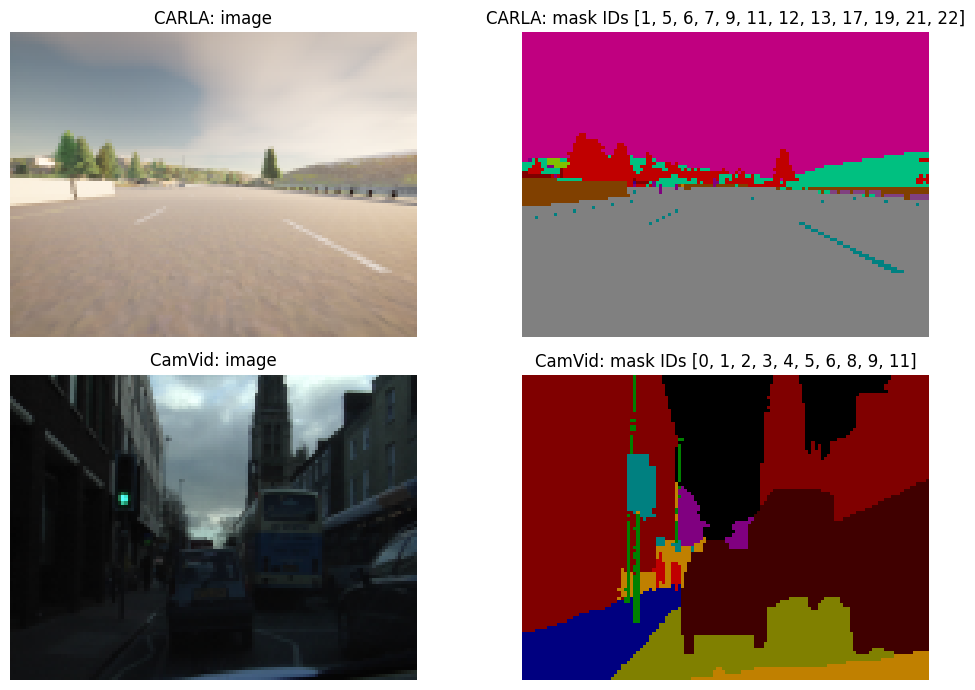

In [2]:
for name, split in [("CARLA", carla_split), ("CamVid", camvid_split)]:
    print(name, {part: len(pairs) for part, pairs in split.items()})
    names = [{image.name for image, _ in pairs} for pairs in split.values()]
    assert not (names[0] & names[1] or names[0] & names[2] or names[1] & names[2])

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, (name, split, classes) in enumerate([
        ("CARLA", carla_split, CARLA_CLASSES), ("CamVid", camvid_split, CAMVID_CLASSES)]):
    image, mask = read_pair(*split["train"][0], (96, 128), len(classes))
    axes[row, 0].imshow(image)
    axes[row, 1].imshow(label_colors(len(classes))[mask[..., 0]])
    axes[row, 0].set_title(name + ": image")
    axes[row, 1].set_title(name + ": mask IDs " + str(np.unique(mask).tolist()))
    for ax in axes[row]: ax.axis("off")
fig.tight_layout()
plt.show()


### Предобработка и распределение классов

Все изображения приводятся OpenCV к **96×128**, переводятся из BGR в RGB и нормализуются в [0, 1] одним делением на 255. Маски остаются целочисленными и изменяют размер только через nearest neighbor. В BGRA-масках CARLA ID хранится в красном канале, alpha=255 не является номером класса.

Проверяется каждая пара файлов: совпадение размеров и диапазон ID. Для всех 23 классов есть отдельные цвета. На графиках ниже показано распределение обучающих пикселей. Оно нужно, чтобы увидеть дисбаланс: редкие пешеходы и знаки влияют на accuracy гораздо меньше дороги и неба.

CamVid Void=11 исключается из loss, accuracy и mean IoU. Предсказание Void на размеченном пикселе считается ошибкой. В CARLA оставлены все 23 класса, включая Unlabeled=0, согласно учебному заданию.


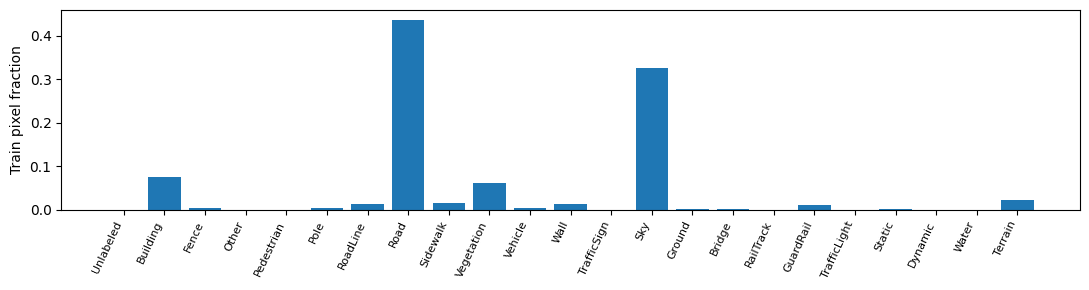

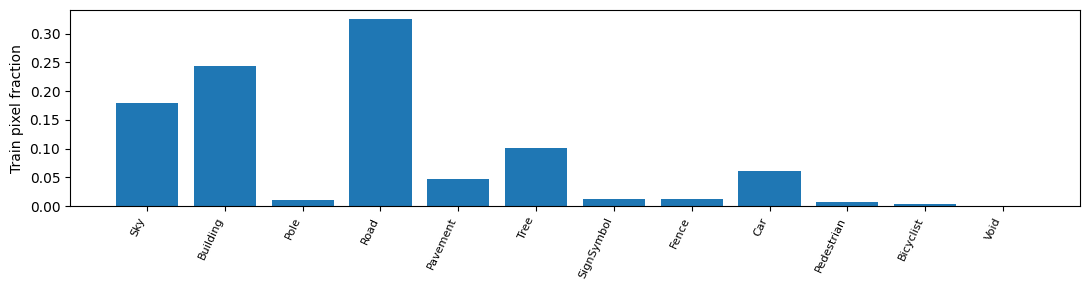

CARLA самый частый класс train: Road
Классы без обучающих пикселей: ['Unlabeled']
CamVid самый частый класс train: Road
Классы без обучающих пикселей: []


In [3]:
carla_stats = inspect_dataset(carla_split, "carla", (96, 128), CARLA_CLASSES)
camvid_stats = inspect_dataset(camvid_split, "camvid", (96, 128), CAMVID_CLASSES, ignore_label=11)
for name, stats in [("CARLA", carla_stats), ("CamVid", camvid_stats)]:
    print(name, "самый частый класс train:", stats["class_names"][stats["majority_class"]])
    print("Классы без обучающих пикселей:", [label for label, count in
          zip(stats["class_names"], stats["train"]["class_pixels"]) if count == 0])


## 2. Построение U-Net

Функции в `lab2.py` реализуют параметры из задания:
- `conv_block`: две Conv2D 3×3 с ReLU, same и he_normal; необязательный Dropout; MaxPooling 2×2;
- `upsampling_block`: Conv2DTranspose 3×3 со stride=2, объединение `[up, skip]`, две Conv2D;
- `unet_model`: пять блоков encoder, четыре decoder, Dropout=0.3 в четвёртом и пятом encoder; последний encoder без pooling; на выходе Conv2D 1×1 с числом каналов по числу классов.

Skip connections возвращают decoder признаки высокого разрешения. Выход содержит logits, поэтому используется `SparseCategoricalCrossentropy(from_logits=True)`, а не отдельный softmax перед loss.


In [4]:
inputs = tf.keras.layers.Input((96, 128, 3))
next_layer, skip = conv_block(inputs, 32)
assert tuple(next_layer.shape) == (None, 48, 64, 32)
assert tuple(skip.shape) == (None, 96, 128, 32)

small = tf.keras.layers.Input((12, 16, 256))
contractive = tf.keras.layers.Input((24, 32, 128))
up = upsampling_block(small, contractive, 32)
assert tuple(up.shape) == (None, 24, 32, 32)

reference_model = unet_model()  # Полная ширина из задания: 32 начальных фильтра.
assert reference_model.output_shape == (None, 96, 128, 23)
print("Параметров в варианте n_filters=32:", reference_model.count_params())
print("Все 23 цвета различаются:", len(np.unique(label_colors(23), axis=0)) == 23)
del reference_model
training_model = unet_model(n_filters=8)
training_model.summary()
del training_model


Параметров в варианте n_filters=32: 8640471
Все 23 цвета различаются: True


Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 96, 128,   │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 96, 128,   │        224 │ input_layer_4[0]… │
│                     │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 96, 128,   │        584 │ conv2d_24[0][0]   │
│                     │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 48, 64, 8) │          0 │ conv2d_25[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 48, 64,    │      1,168 │ max_pooling2d_5[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 48, 64,    │      2,320 │ conv2d_26[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 24, 32,    │          0 │ conv2d_27[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 24, 32,    │      4,640 │ max_pooling2d_6[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 24, 32,    │      9,248 │ conv2d_28[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 12, 16,    │          0 │ conv2d_29[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 12, 16,    │     18,496 │ max_pooling2d_7[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 12, 16,    │     36,928 │ conv2d_30[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 12, 16,    │          0 │ conv2d_31[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 6, 8, 64)  │          0 │ dropout_2[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 6, 8, 128) │     73,856 │ max_pooling2d_8[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 6, 8, 128) │    147,584 │ conv2d_32[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 6, 8, 128) │          0 │ conv2d_33[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_5  │ (None, 12, 16,    │     73,792 │ dropout_3[0][0] 

 Total params: 540,999 (2.06 MB)

 Trainable params: 540,999 (2.06 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Обучение на CARLA

В обоих экспериментах используется Adam, batch size 8 и **40 эпох**. Для CPU начальное число фильтров уменьшено с 32 до 8: encoder имеет ширины 8, 16, 32, 64, 128. Все блоки и skip connections сохранены. Это уменьшает вычислительную стоимость; результаты относятся именно к уменьшенной модели. Вариант с 32 фильтрами проверен выше и доступен через параметр `n_filters`.

Модель выбирается по минимальному validation loss. Тестовая часть не используется для выбора эпохи или настройки модели. Графики содержат train и validation loss/accuracy; историю каждой эпохи сохраняю в CSV.


carla: загружен выполненный эксперимент (40 эпох), лучшая эпоха 18


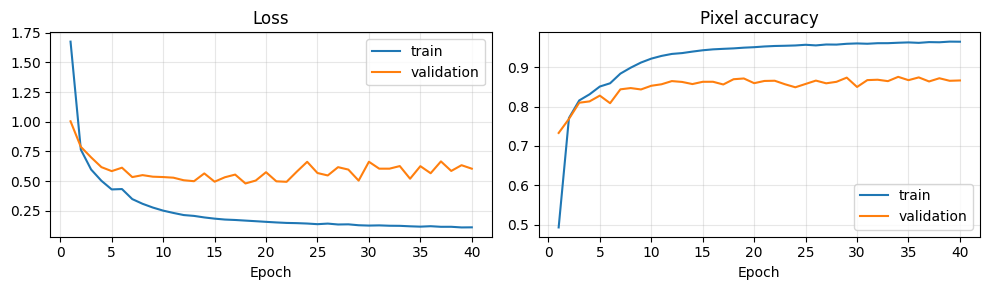

In [5]:
EPOCHS = 40
N_FILTERS = 8

carla_model, carla_history = train_model(
    carla_split, "carla", size=(96, 128), n_classes=23,
    epochs=EPOCHS, n_filters=N_FILTERS, reuse_existing=not RETRAIN)
plot_history(carla_history, "carla")


### Оценка CARLA

Pixel accuracy — доля правильных пикселей. IoU класса — пересечение настоящей и предсказанной области, делённое на объединение. Mean IoU усредняет классы, поэтому лучше показывает ошибки на небольших объектах. Класс без истинных и предсказанных пикселей не включается в среднее; его IoU помечается как отсутствующий.

Для сравнения использую простой baseline: всегда предсказывать самый частый **обучающий** класс. Он не использует метки теста для выбора класса. Если U-Net не превосходит такой baseline, одной высокой accuracy было бы недостаточно.


CARLA: accuracy=0.8832, mean IoU=0.2599
Baseline: {'class': 7, 'accuracy': 0.37307221034787735, 'mean_iou': 0.02072623390821541}


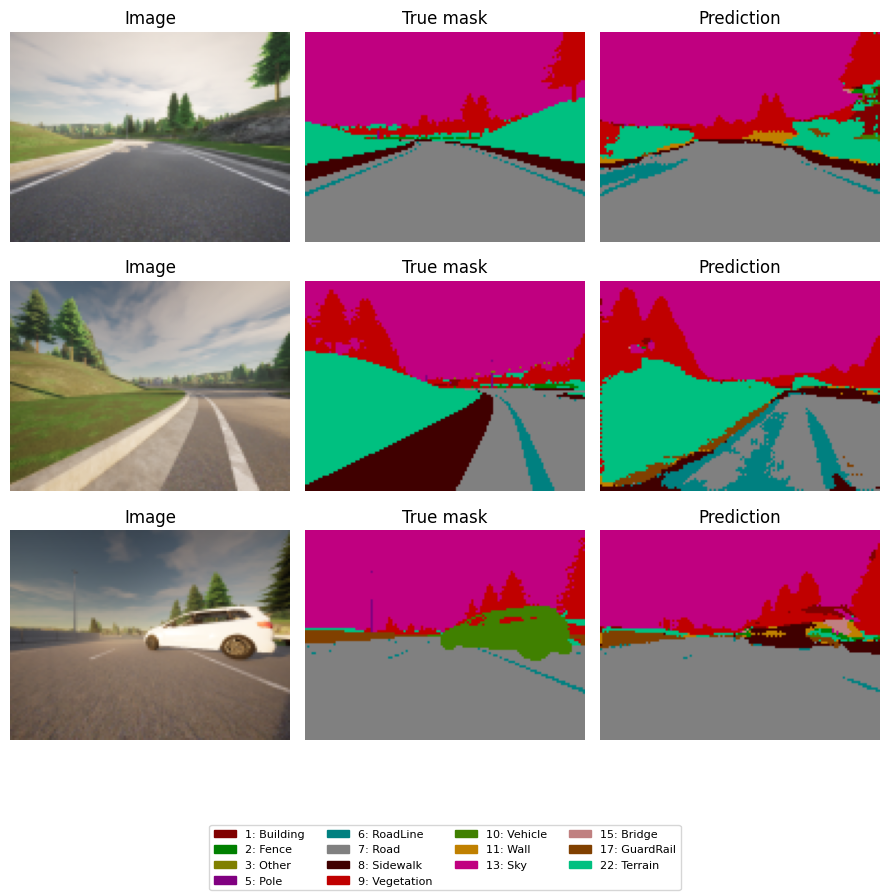

In [6]:
carla_scores = evaluate_model(
    carla_model, carla_split["test"], (96, 128), 23, "carla",
    baseline_class=carla_stats["majority_class"], class_names=CARLA_CLASSES)
print(f"CARLA: accuracy={carla_scores['accuracy']:.4f}, mean IoU={carla_scores['mean_iou']:.4f}")
print("Baseline:", {key: carla_scores["majority_baseline"][key] for key in ["class", "accuracy", "mean_iou"]})
show_predictions(carla_model, carla_split["test"], (96, 128), 23,
                 "carla", class_names=CARLA_CLASSES)


## 4. Второй эксперимент: CamVid

Повторяю предобработку, обучение и оценку на реальных изображениях. В модели 12 выходных каналов: 11 смысловых классов и Void. Пиксели с настоящей меткой Void не участвуют в функции потерь и метриках, но предсказание Void на других пикселях штрафуется как ошибка.

Размер входа, число начальных фильтров, Adam, batch size и число эпох такие же, как в первом эксперименте. Веса обучаются заново: переноса весов с CARLA нет.


camvid: загружен выполненный эксперимент (40 эпох), лучшая эпоха 40


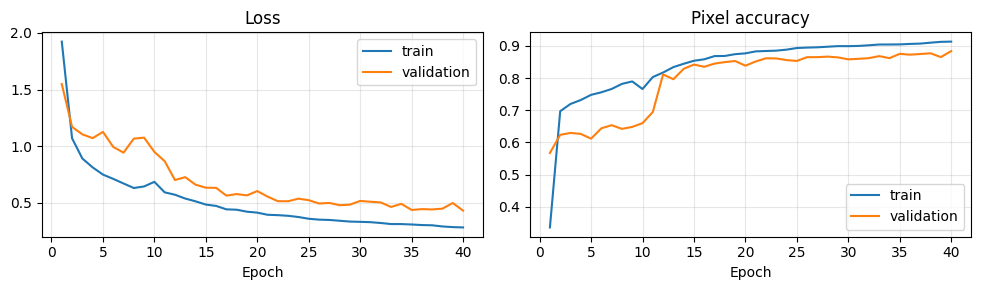

CamVid: accuracy=0.7861, mean IoU=0.3539
Baseline: {'class': 3, 'accuracy': 0.26387527538984606, 'mean_iou': 0.023988661399076915}


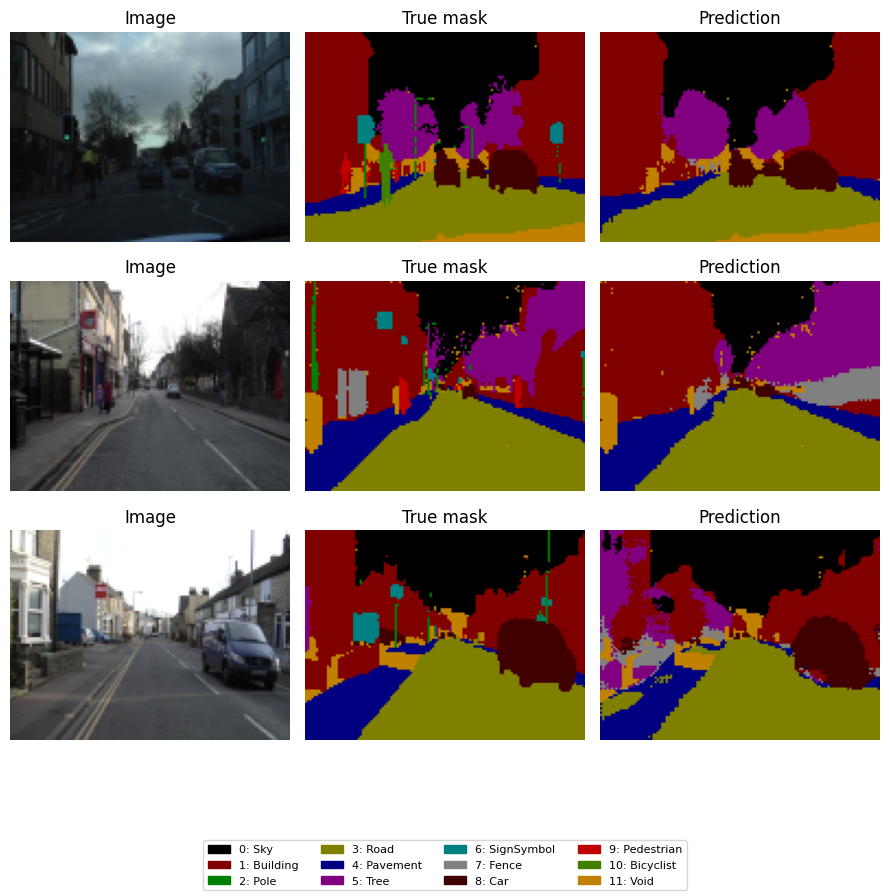

In [7]:
camvid_model, camvid_history = train_model(
    camvid_split, "camvid", size=(96, 128), n_classes=12,
    epochs=EPOCHS, n_filters=N_FILTERS, ignore_label=11, reuse_existing=not RETRAIN)
plot_history(camvid_history, "camvid")
camvid_scores = evaluate_model(
    camvid_model, camvid_split["test"], (96, 128), 12, "camvid", ignore_label=11,
    baseline_class=camvid_stats["majority_class"], class_names=CAMVID_CLASSES)
print(f"CamVid: accuracy={camvid_scores['accuracy']:.4f}, mean IoU={camvid_scores['mean_iou']:.4f}")
print("Baseline:", {key: camvid_scores["majority_baseline"][key] for key in ["class", "accuracy", "mean_iou"]})
show_predictions(camvid_model, camvid_split["test"], (96, 128), 12,
                 "camvid", class_names=CAMVID_CLASSES, ignore_label=11)


## 5. Разбор ошибок

Ниже приведены все поклассовые IoU и количество оцениваемых тестовых пикселей (без Void). Нулевое качество редких классов не скрывается общей accuracy. Для визуального разбора выбираю два **худших** тестовых кадра из разных временных групп по среднему IoU изображения, а не самые удачные примеры.


### CARLA

| Класс | Оцениваемых пикселей | IoU |
| --- | ---: | ---: |
| Unlabeled | 0 | не оценивается |
| Building | 30785 | 0.501 |
| Fence | 6594 | 0.003 |
| Other | 454 | 0.000 |
| Pedestrian | 177 | 0.000 |
| Pole | 1841 | 0.001 |
| RoadLine | 33749 | 0.354 |
| Road | 485937 | 0.910 |
| Sidewalk | 49979 | 0.409 |
| Vegetation | 121194 | 0.676 |
| Vehicle | 12947 | 0.076 |
| Wall | 4 | 0.000 |
| TrafficSign | 199 | 0.000 |
| Sky | 450261 | 0.968 |
| Ground | 0 | 0.000 |
| Bridge | 385 | 0.000 |
| RailTrack | 0 | не оценивается |
| GuardRail | 7328 | 0.443 |
| TrafficLight | 0 | не оценивается |
| Static | 7067 | 0.000 |
| Dynamic | 2680 | 0.000 |
| Water | 0 | не оценивается |
| Terrain | 90947 | 0.597 |

Частые ошибки (истинный → предсказанный):
Terrain → Vegetation: 13998 пикселей
RoadLine → Road: 13956 пикселей
Road → Sidewalk: 10483 пикселей
Vegetation → Building: 10204 пикселей
Sidewalk → Road: 10012 пикселей
Худшие кадры из разных временных групп: ['data/carla/images/test/007772.png', 'data/carla/images/test/004095.png']


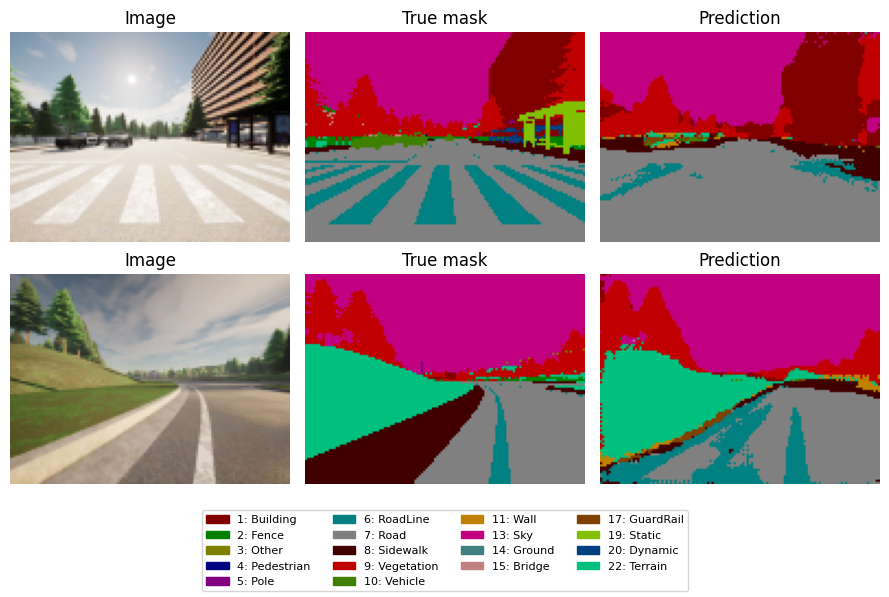

### CamVid

| Класс | Оцениваемых пикселей | IoU |
| --- | ---: | ---: |
| Sky | 497502 | 0.875 |
| Building | 706359 | 0.622 |
| Pole | 34018 | 0.000 |
| Road | 727145 | 0.836 |
| Pavement | 265356 | 0.500 |
| Tree | 325017 | 0.448 |
| SignSymbol | 29146 | 0.000 |
| Fence | 34194 | 0.058 |
| Car | 113145 | 0.553 |
| Pedestrian | 18335 | 0.000 |
| Bicyclist | 5422 | 0.000 |
| Void | 0 | не оценивается |

Частые ошибки (истинный → предсказанный):
Building → Tree: 96354 пикселей
Pavement → Road: 95890 пикселей
Tree → Building: 80922 пикселей
Sky → Tree: 25280 пикселей
Road → Pavement: 22856 пикселей
Худшие кадры из разных временных групп: ['data/camvid/images/test/0001TP_009990.png', 'data/camvid/images/test/Seq05VD_f02610.png']


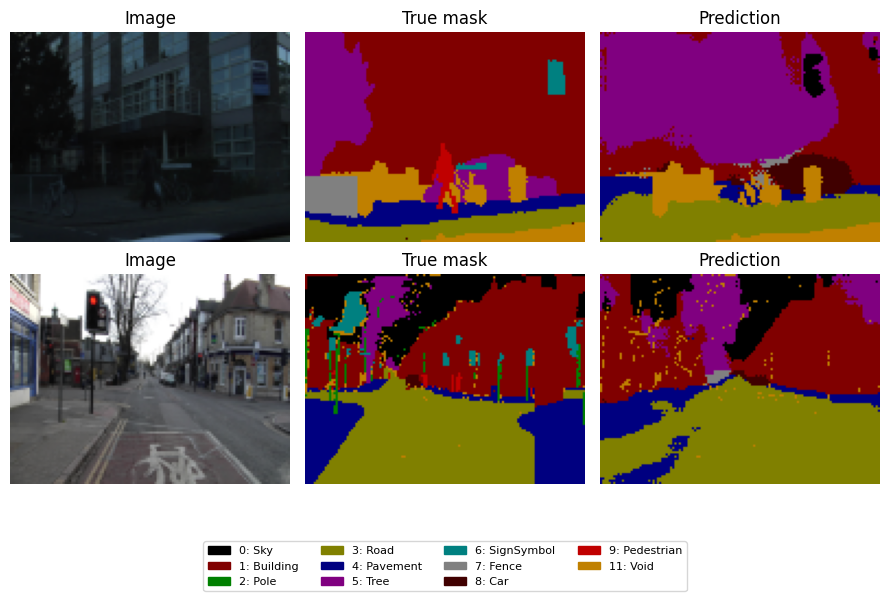

In [8]:
for name, scores, split, model, classes in [
        ("CARLA", carla_scores, carla_split, carla_model, CARLA_CLASSES),
        ("CamVid", camvid_scores, camvid_split, camvid_model, CAMVID_CLASSES)]:
    rows = ["| Класс | Оцениваемых пикселей | IoU |", "| --- | ---: | ---: |"]
    for label, count, score in zip(classes, scores["class_pixels"], scores["iou_per_class"]):
        rows.append(f"| {label} | {count} | {score:.3f} |" if score is not None
                    else f"| {label} | {count} | не оценивается |")
    display(Markdown("### " + name + "\n\n" + "\n".join(rows)))
    cm = np.array(scores["confusion_matrix"])
    np.fill_diagonal(cm, 0)
    errors = sorted(zip(*np.nonzero(cm)), key=lambda ij: cm[ij], reverse=True)[:5]
    print("Частые ошибки (истинный → предсказанный):")
    for true, pred in errors:
        print(f"{classes[true]} → {classes[pred]}: {cm[true, pred]} пикселей")
    selected = worst_pairs(scores, split["test"])
    print("Худшие кадры из разных временных групп:", [str(image) for image, _ in selected])
    show_predictions(model, selected, (96, 128), len(classes),
                     name.lower() + "_worst", count=2, class_names=classes, ignore_label=11 if name == "CamVid" else None)


## 6. Сравнение и вывод

CARLA содержит изображения симулятора, CamVid — реальные дорожные сцены. Их метрики нельзя напрямую трактовать как сравнение качества наборов: отличаются классы, распределение объектов и разбиения. Важнее сравнить каждую модель с её собственным baseline и посмотреть поклассовые ошибки.


In [9]:
rows = ["| Набор | Тестовых кадров | U-Net accuracy | Baseline accuracy | U-Net mIoU | Baseline mIoU | Лучшая эпоха |",
        "| --- | ---: | ---: | ---: | ---: | ---: | ---: |"]
for name, scores in [("carla", carla_scores), ("camvid", camvid_scores)]:
    run = json.loads(Path(f"results/{name}_run.json").read_text())
    baseline = scores["majority_baseline"]
    rows.append(f"| {name} | {scores['test_images']} | {scores['accuracy']:.3f} | "
                f"{baseline['accuracy']:.3f} | {scores['mean_iou']:.3f} | "
                f"{baseline['mean_iou']:.3f} | {run['best_epoch']} |")
display(Markdown("\n".join(rows)))
display(Markdown(
    "U-Net обучена и проверена на двух наборах. Skip connections помогают восстановить "
    "границы, но низкое разрешение 96×128 и дисбаланс классов затрудняют распознавание "
    "тонких и небольших объектов. В следующем эксперименте используется "
    "взвешенная функция потерь. Результаты относятся к одной инициализации seed=42 "
    "и уменьшенной модели с 8 начальными фильтрами; независимость всех поездок "
    "по одному лишь разбиению кадров гарантировать нельзя."))


| Набор | Тестовых кадров | U-Net accuracy | Baseline accuracy | U-Net mIoU | Baseline mIoU | Лучшая эпоха |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| carla | 106 | 0.883 | 0.373 | 0.260 | 0.021 | 18 |
| camvid | 233 | 0.786 | 0.264 | 0.354 | 0.024 | 40 |

U-Net обучена и проверена на двух наборах. Skip connections помогают восстановить границы, но низкое разрешение 96×128 и дисбаланс классов затрудняют распознавание тонких и небольших объектов. В следующем эксперименте используется взвешенная функция потерь. Результаты относятся к одной инициализации seed=42 и уменьшенной модели с 8 начальными фильтрами; независимость всех поездок по одному лишь разбиению кадров гарантировать нельзя.

## 7. Дополнительный эксперимент с полной шириной U-Net

Использую 32 начальных фильтра и 40 эпох, как в исходном примере. Редкие классы учитываются взвешенной crossentropy; веса вычислены по train. Лучшая эпоха выбирается по mean IoU на validation. Ниже загружаются результаты обучения, сохранённые скриптами `experiment_32.py` и `compare_32.py`.

| Набор | Validation IoU, 8 фильтров | Validation IoU, 32 фильтра | Test IoU, 8 фильтров | Test IoU, 32 фильтра | Выбор по validation |
| --- | ---: | ---: | ---: | ---: | ---: |
| CARLA | 0.222 | 0.278 | 0.260 | 0.247 | 32 |
| CAMVID | 0.468 | 0.585 | 0.354 | 0.446 | 32 |

Средний IoU только по классам, присутствующим в тестовой разметке:

| Набор | Классов в разметке | mIoU: 8 фильтров | mIoU: 32 фильтра |
| --- | ---: | ---: | ---: |
| CARLA | 18 | 0.274 | 0.302 |
| CAMVID | 11 | 0.354 | 0.446 |

### CARLA

| Класс | Пиксели | IoU: 8 фильтров | IoU: 32 фильтра |
| --- | ---: | ---: | ---: |
| Unlabeled | 0 | — | — |
| Building | 30785 | 0.501 | 0.484 |
| Fence | 6594 | 0.003 | 0.202 |
| Other | 454 | 0.000 | 0.007 |
| Pedestrian | 177 | 0.000 | 0.002 |
| Pole | 1841 | 0.001 | 0.044 |
| RoadLine | 33749 | 0.354 | 0.451 |
| Road | 485937 | 0.910 | 0.920 |
| Sidewalk | 49979 | 0.409 | 0.454 |
| Vegetation | 121194 | 0.676 | 0.722 |
| Vehicle | 12947 | 0.076 | 0.247 |
| Wall | 4 | 0.000 | 0.000 |
| TrafficSign | 199 | 0.000 | 0.000 |
| Sky | 450261 | 0.968 | 0.963 |
| Ground | 0 | 0.000 | 0.000 |
| Bridge | 385 | 0.000 | 0.000 |
| RailTrack | 0 | — | 0.000 |
| GuardRail | 7328 | 0.443 | 0.380 |
| TrafficLight | 0 | — | 0.000 |
| Static | 7067 | 0.000 | 0.002 |
| Dynamic | 2680 | 0.000 | 0.004 |
| Water | 0 | — | 0.000 |
| Terrain | 90947 | 0.597 | 0.559 |

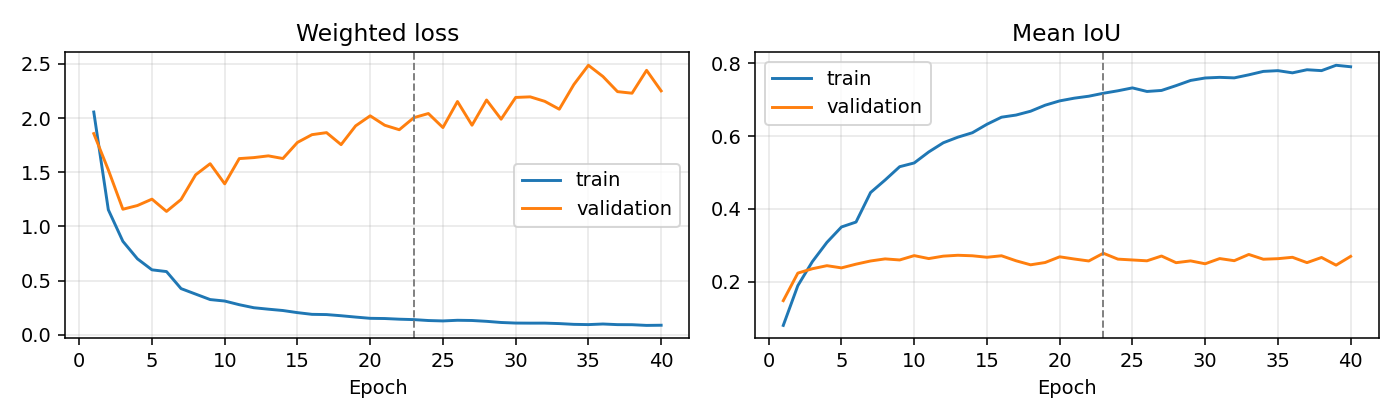

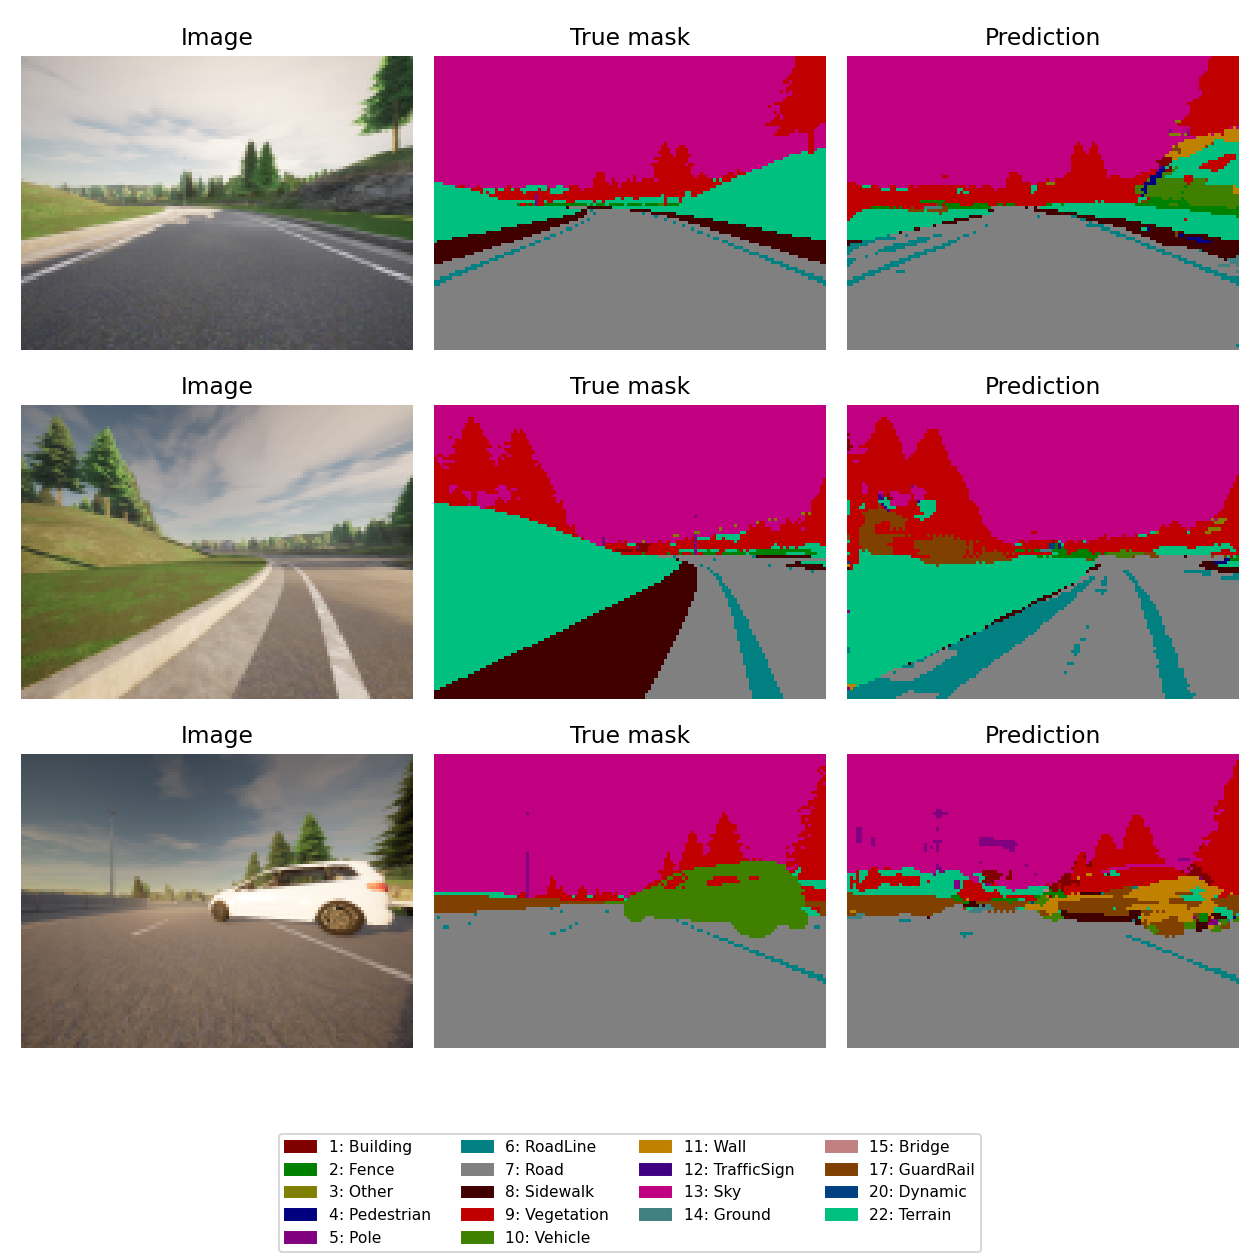

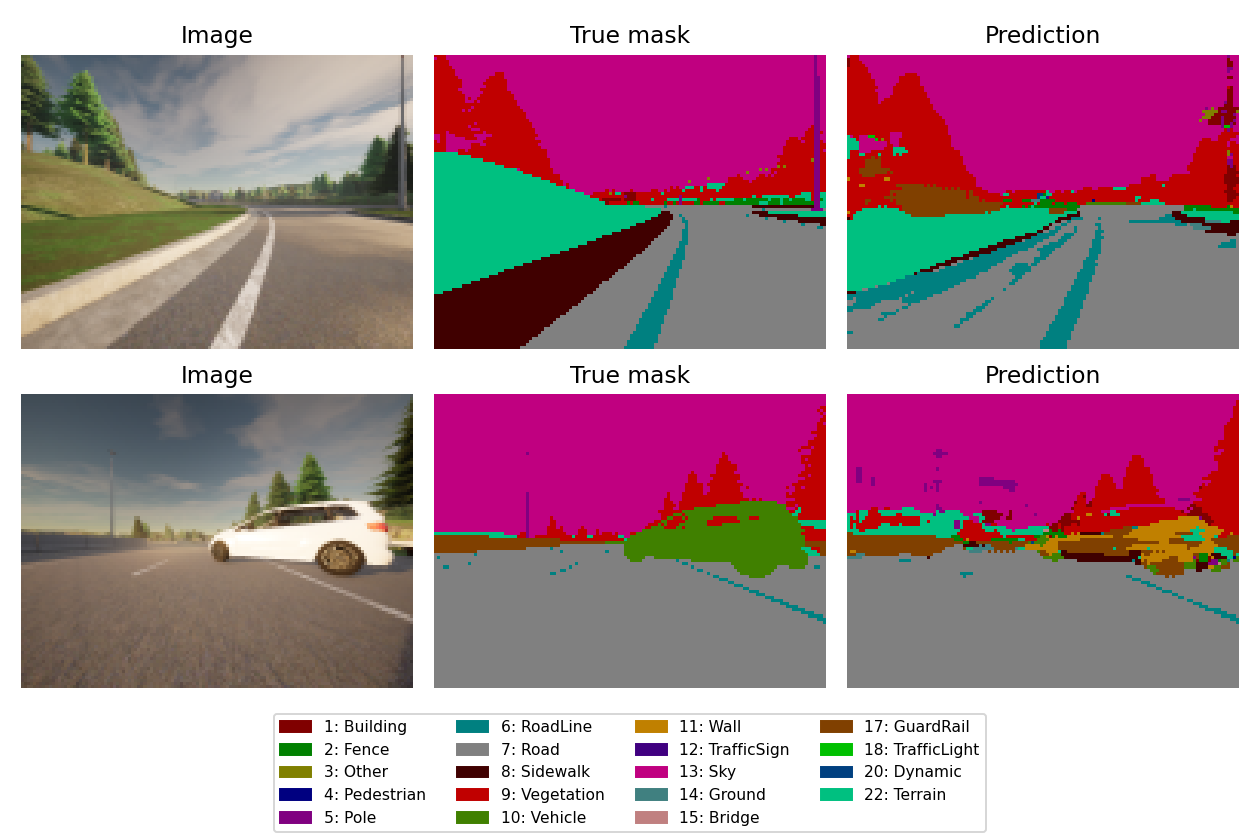

### CAMVID

| Класс | Пиксели | IoU: 8 фильтров | IoU: 32 фильтра |
| --- | ---: | ---: | ---: |
| Sky | 497502 | 0.875 | 0.887 |
| Building | 706359 | 0.622 | 0.574 |
| Pole | 34018 | 0.000 | 0.103 |
| Road | 727145 | 0.836 | 0.867 |
| Pavement | 265356 | 0.500 | 0.612 |
| Tree | 325017 | 0.448 | 0.527 |
| SignSymbol | 29146 | 0.000 | 0.140 |
| Fence | 34194 | 0.058 | 0.103 |
| Car | 113145 | 0.553 | 0.649 |
| Pedestrian | 18335 | 0.000 | 0.246 |
| Bicyclist | 5422 | 0.000 | 0.201 |
| Void | 0 | — | — |

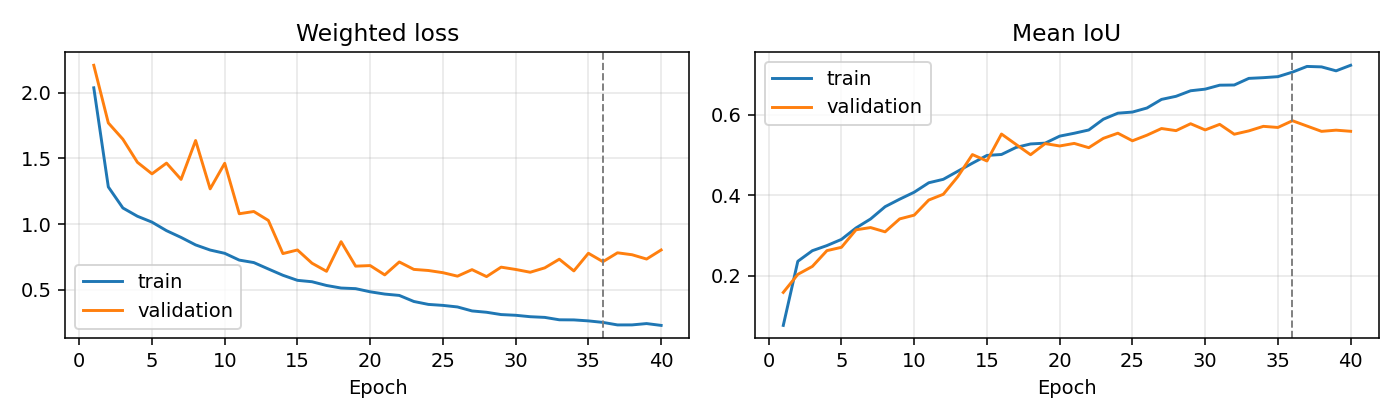

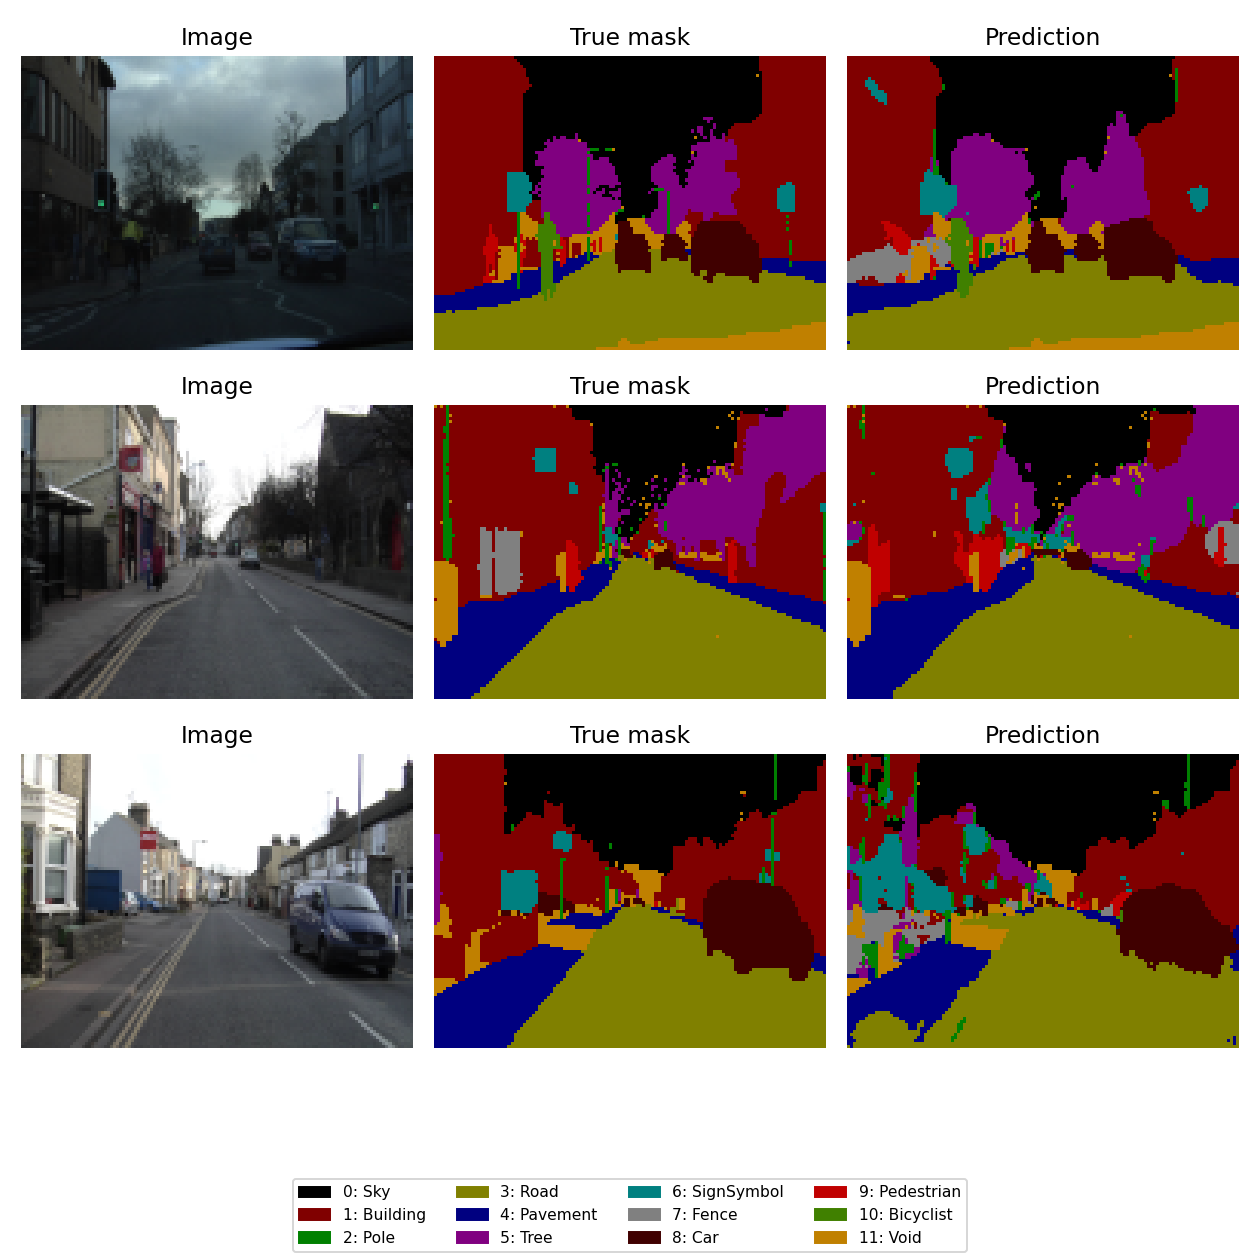

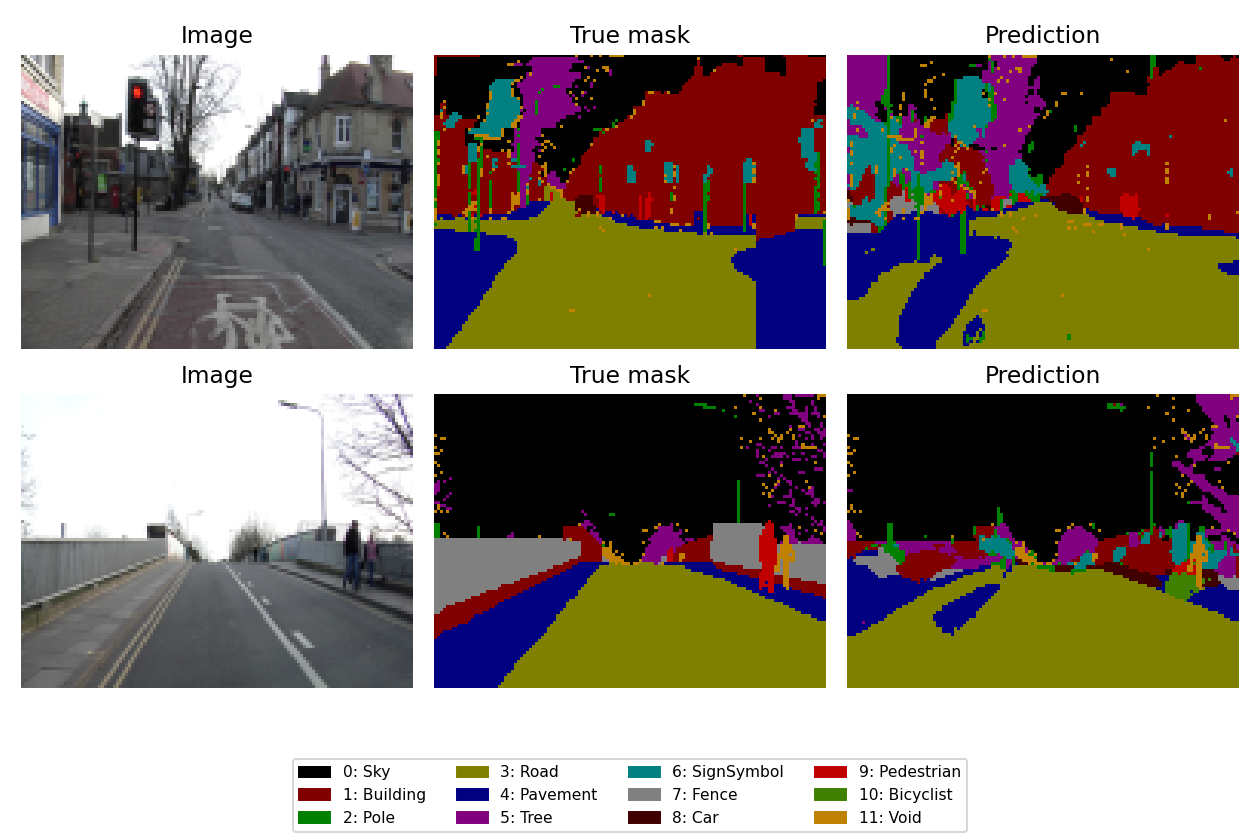

In [10]:
from IPython.display import Image
from update_work import comparison_table, present_classes_table, read_comparison
display(Markdown(comparison_table()))
display(Markdown("Средний IoU только по классам, присутствующим в тестовой разметке:\n\n" + present_classes_table()))
for name in ["carla", "camvid"]:
    result = read_comparison(name)
    metrics = json.loads(Path(f"results/experiment_32/{name}_new_test_metrics.json").read_text())
    rows = ["| Класс | Пиксели | IoU: 8 фильтров | IoU: 32 фильтра |", "| --- | ---: | ---: | ---: |"]
    for label, pixels, old, new in zip(result["classes"], metrics["class_pixels"],
                                       result["test_iou_per_class"]["8"], result["test_iou_per_class"]["32"]):
        old_text = f"{old:.3f}" if old is not None else "—"
        new_text = f"{new:.3f}" if new is not None else "—"
        rows.append(f"| {label} | {pixels} | {old_text} | {new_text} |")
    display(Markdown("### " + name.upper() + "\n\n" + "\n".join(rows)))
    for kind in ["curves", "predictions", "worst_predictions"]:
        display(Image(filename=f"results/experiment_32/{name}_{kind}.png"))


Тестовый набор использовался при анализе модели с 8 фильтрами, поэтому сравнение на нём носит исследовательский характер. Дополнительная проверка на новых кадрах приведена ниже.

## 8. Проверка на другом наборе CARLA

Контрольные 223 кадра из другого опубликованного набора не участвовали в обучении и выборе модели. В этой версии CARLA поддерживаются классы 1–12; Unlabeled=0 исключается, а ошибки предсказания других классов учитываются. На иллюстрациях исключённые области замаскированы. Пешеходов в контрольной части нет. Данные и ограничения сравнения описаны в отчёте.

| Модель | Pixel accuracy | Mean IoU по классам 1–12 |
| --- | ---: | ---: |
| Baseline: Road | 0.503 | 0.046 |
| U-Net, 8 фильтров | 0.480 | 0.146 |
| U-Net, 32 фильтра | 0.656 | 0.247 |

Оценено пикселей: 1808785 из 2740224


| Класс | Пиксели | IoU: 8 фильтров | IoU: 32 фильтра |
| --- | ---: | ---: | ---: |
| Building | 286498 | 0.371 | 0.529 |
| Fence | 1284 | 0.002 | 0.002 |
| Other | 5047 | 0.000 | 0.006 |
| Pedestrian | 0 | — | — |
| Pole | 69207 | 0.001 | 0.034 |
| RoadLine | 55009 | 0.103 | 0.268 |
| Road | 909174 | 0.547 | 0.748 |
| Sidewalk | 103666 | 0.164 | 0.238 |
| Vegetation | 71712 | 0.325 | 0.526 |
| Vehicle | 180102 | 0.008 | 0.357 |
| Wall | 125222 | 0.089 | 0.004 |
| TrafficSign | 1864 | 0.000 | 0.000 |

Ошибочные предсказания пешеходов, 8 фильтров: 0 пикселей
Ошибочные предсказания пешеходов, 32 фильтров: 20054 пикселей


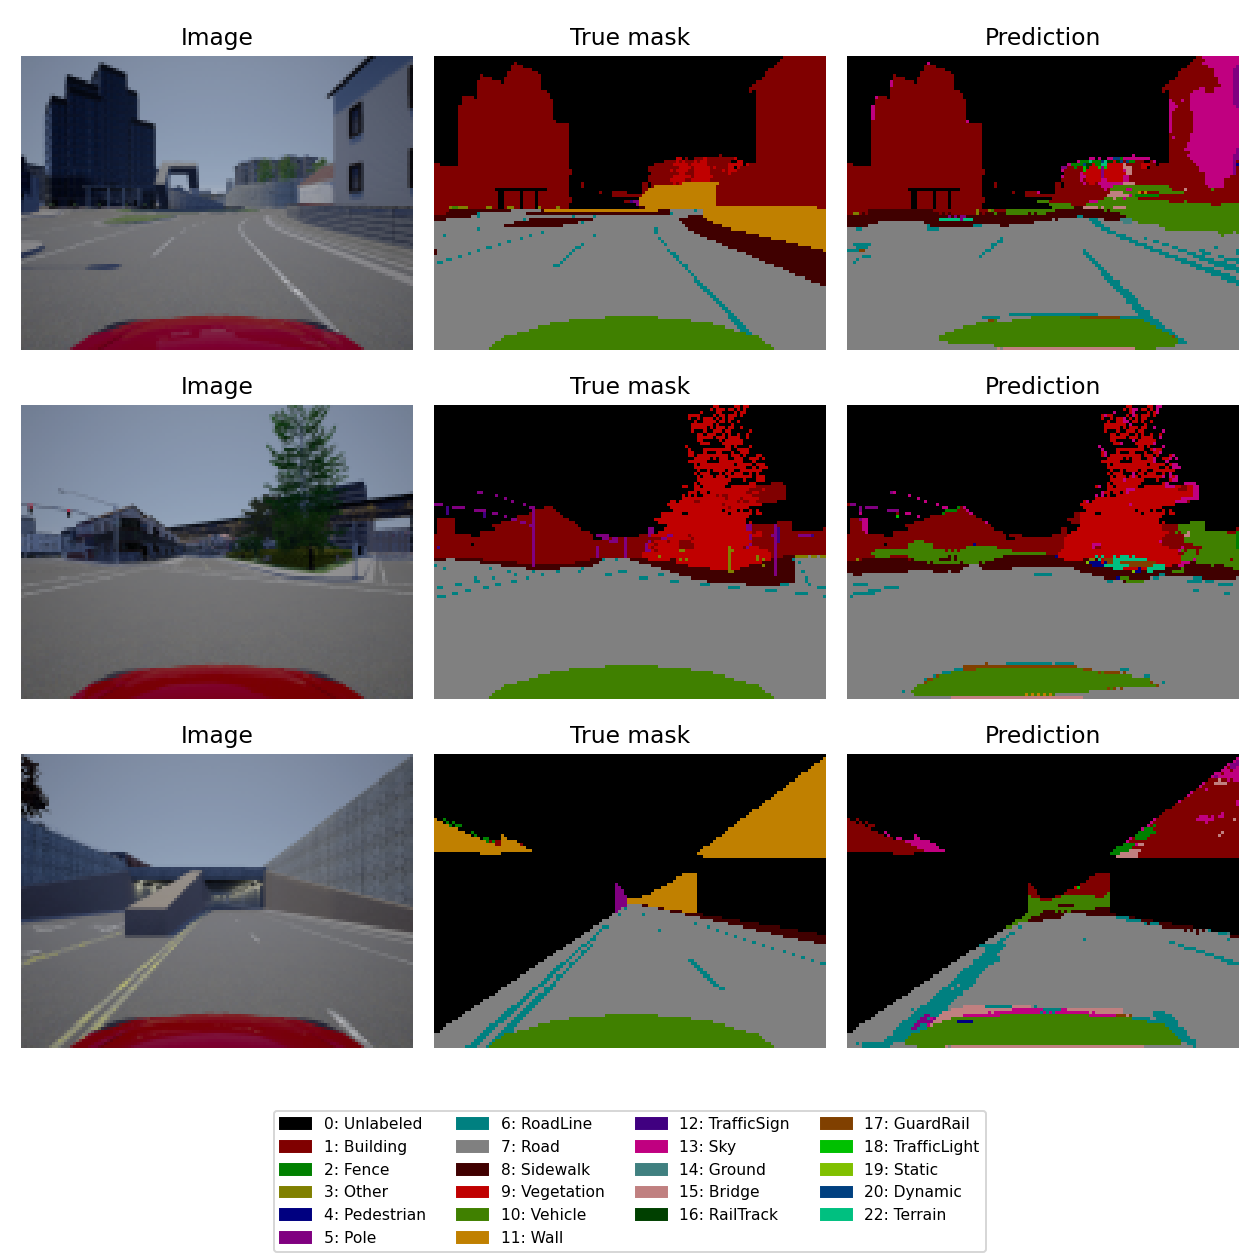

In [11]:
from update_work import external_table
display(Markdown(external_table()))
external = json.loads(Path("results/experiment_32/carla_external_metrics.json").read_text())
valid_pixels = external["models"]["8"]["evaluated_pixels"]
print("Оценено пикселей:", valid_pixels, "из", external["images"] * 96 * 128)
rows = ["| Класс | Пиксели | IoU: 8 фильтров | IoU: 32 фильтра |",
        "| --- | ---: | ---: | ---: |"]
for label in range(1, 13):
    old = external["models"]["8"]["iou_per_class"][label]
    new = external["models"]["32"]["iou_per_class"][label]
    pixels = external["models"]["8"]["class_pixels"][label]
    old_text = f"{old:.3f}" if old is not None else "—"
    new_text = f"{new:.3f}" if new is not None else "—"
    rows.append(f"| {CARLA_CLASSES[label]} | {pixels} | {old_text} | {new_text} |")
display(Markdown("\n".join(rows)))
for width in ["8", "32"]:
    false_pedestrian = sum(row[4] for row in external["models"][width]["confusion_matrix"])
    print(f"Ошибочные предсказания пешеходов, {width} фильтров: {false_pedestrian} пикселей")
display(Image(filename="results/experiment_32/carla_external_predictions.png"))


## 9. Собственные фотографии

Для визуальной проверки использую четыре собственные фотографии. Показываю предсказания обеих обученных моделей после изменения размера до 96×128. Масок для этих фотографий нет, поэтому IoU на них не вычисляется. Горные виды отличаются от дорожных сцен обучения; мелкие объекты и границы часто распознаются неверно.

CARLA


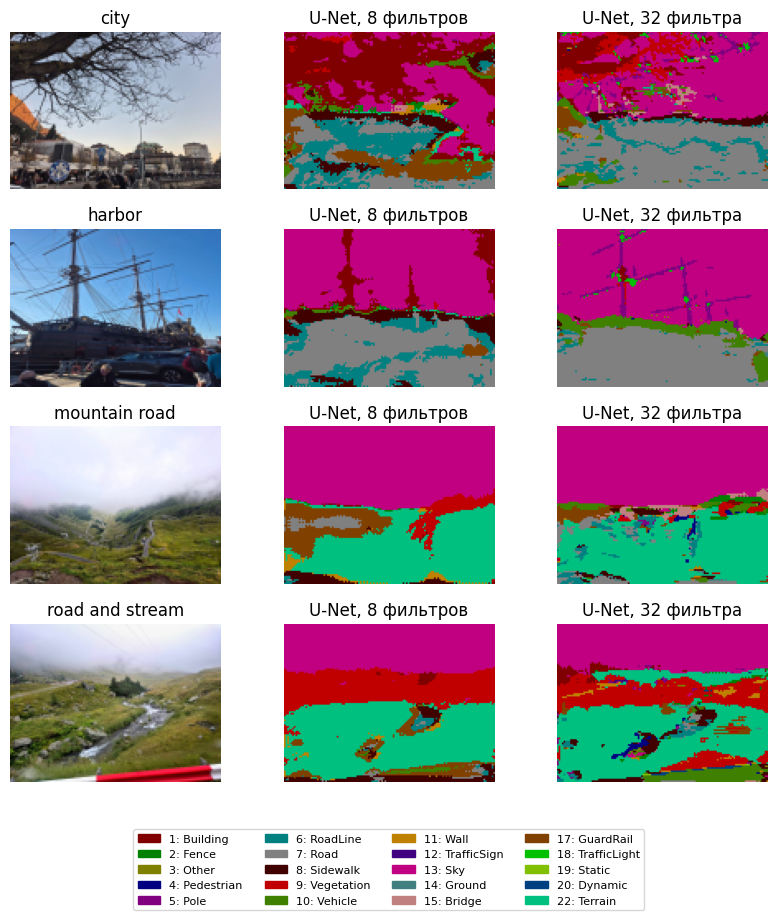

CAMVID


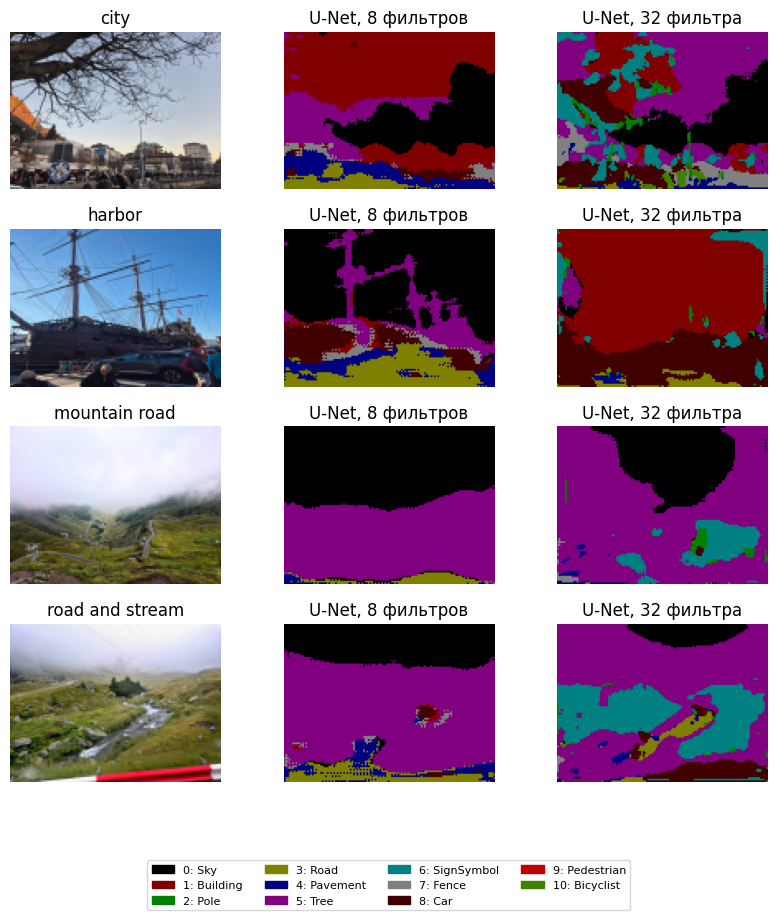

In [12]:
from own_photos import show_own_photos
for dataset in ["carla", "camvid"]:
    print(dataset.upper())
    _ = show_own_photos(dataset)
